In [1]:
import jax

import matplotlib.pyplot as plt

from agfx.gym import create_state, enumerate_ancestral_graphs
from agfx.rewards import create_log_reward, LogRewardType 
from agfx.training import train, LossType
from agfx.policies import GFlowNet
from agfx.evals import eval_marginal
from agfx.special.linear_gaussian import sample_linear_gaussian

In [2]:
num_nodes = 5
bs = 64
dmid = 64

iterations = int(5e3)
logr_t = LogRewardType.BIC
loss_t = LossType.CB

seeds = [42 * (i + 1) for i in range(10)]


In [3]:
all_graphs = enumerate_ancestral_graphs(num_nodes, has_confounding=False)

In [4]:
def run(seed: int):
    key = jax.random.key(seed)
    k1, k2, k3 = jax.random.split(key, 3)

    data, dir_amat, bidir_amat, *_ = sample_linear_gaussian(
        k1, num_nodes, num_samples=20
    )

    state = create_state(bs, num_nodes, has_confounding=False)
    # Create the GFlowNet
    gfn = GFlowNet(num_nodes, dmid)
    
    # Create the reward function
    logr = create_log_reward(logr_t, data)

    gfn, losses = train(gfn, state, k2, logr, iterations, loss_t)
    
    true_marginals, estimated_marginals = eval_marginal(gfn, state, logr, all_graphs, k3, should_eval_gt=True)

    return true_marginals, estimated_marginals

In [5]:
tmarg = []
emarg = [] 

for seed in seeds:
    tmarg_alpha, emarg_alpha = run(seed=seed)

    tmarg.append(tmarg_alpha)
    emarg.append(emarg_alpha)

100%|██████████| 5000/5000 [00:17<00:00, 292.56it/s, loss=3.76e-01]


true [[0.61415696 0.13549916 0.25035742 0.        ]
 [0.01151281 0.708129   0.28037176 0.        ]
 [0.19434072 0.48512664 0.3205463  0.        ]
 [0.59584194 0.25237277 0.15179884 0.        ]
 [0.08550048 0.7651284  0.14938478 0.        ]
 [0.90596455 0.0539477  0.04010141 0.        ]
 [0.8406101  0.11817878 0.04122481 0.        ]
 [0.8870011  0.06597962 0.04703265 0.        ]
 [0.15200466 0.48741233 0.36059675 0.        ]
 [0.8723638  0.06325626 0.06439367 0.        ]]
estimated [[0.636875   0.1371875  0.2259375  0.        ]
 [0.00515625 0.7523437  0.24249999 0.        ]
 [0.19156249 0.48484373 0.32359374 0.        ]
 [0.6040625  0.24890624 0.14703125 0.        ]
 [0.059375   0.784375   0.15625    0.        ]
 [0.9110937  0.053125   0.03578125 0.        ]
 [0.8675     0.09906249 0.0334375  0.        ]
 [0.9004687  0.05203125 0.0475     0.        ]
 [0.1371875  0.5001562  0.36265624 0.        ]
 [0.88624996 0.06015625 0.05359375 0.        ]]


100%|██████████| 5000/5000 [00:15<00:00, 329.62it/s, loss=2.60e-03]


true [[0.90753955 0.04624202 0.04620799 0.        ]
 [0.86493427 0.0673173  0.0677382  0.        ]
 [0.8164038  0.09154895 0.09203698 0.        ]
 [0.8651246  0.06725574 0.06760943 0.        ]
 [0.9067847  0.04657447 0.04663058 0.        ]
 [0.8364233  0.08171429 0.08185221 0.        ]
 [0.89681673 0.05153868 0.05163427 0.        ]
 [0.9004302  0.04988035 0.04967926 0.        ]
 [0.90770507 0.04614259 0.046142   0.        ]
 [0.9049159  0.04745197 0.04762196 0.        ]]
estimated [[0.9079687  0.0440625  0.04796875 0.        ]
 [0.86828125 0.06921875 0.0625     0.        ]
 [0.81125    0.0946875  0.0940625  0.        ]
 [0.86531246 0.06390624 0.07078125 0.        ]
 [0.9014062  0.04921875 0.049375   0.        ]
 [0.83484375 0.08015625 0.085      0.        ]
 [0.8951562  0.05390625 0.0509375  0.        ]
 [0.9040625  0.04640625 0.04953125 0.        ]
 [0.9079687  0.04828125 0.04375    0.        ]
 [0.91046876 0.0434375  0.04609375 0.        ]]


100%|██████████| 5000/5000 [00:15<00:00, 325.49it/s, loss=5.51e-02]


true [[0.9098921  0.04588694 0.04421367 0.        ]
 [0.89398354 0.05318612 0.05282309 0.        ]
 [0.8962777  0.05109876 0.05261612 0.        ]
 [0.90712434 0.04710732 0.045761   0.        ]
 [0.7080093  0.17939638 0.11258675 0.        ]
 [0.5487328  0.11369994 0.33756006 0.        ]
 [0.00260295 0.4544802  0.5429094  0.        ]
 [0.73414505 0.12483953 0.14100805 0.        ]
 [0.7196684  0.11751452 0.16280983 0.        ]
 [0.67849594 0.22544117 0.0960554  0.        ]]
estimated [[0.90749997 0.04671875 0.04578125 0.        ]
 [0.895625   0.05375    0.050625   0.        ]
 [0.90156245 0.04640625 0.05203125 0.        ]
 [0.9060937  0.04453125 0.049375   0.        ]
 [0.7214062  0.17015624 0.1084375  0.        ]
 [0.56046873 0.10921875 0.3303125  0.        ]
 [0.00171875 0.44609374 0.5521875  0.        ]
 [0.7409375  0.12249999 0.1365625  0.        ]
 [0.7232812  0.11984374 0.156875   0.        ]
 [0.6982812  0.2134375  0.08828125 0.        ]]


... (10 outputs left out)

100%|██████████| 5000/5000 [00:13<00:00, 369.20it/s, loss=5.40e-02]


true [[8.0816245e-01 9.4377175e-02 9.7455204e-02 0.0000000e+00]
 [9.0643793e-01 4.4645153e-02 4.8911810e-02 0.0000000e+00]
 [6.8456703e-01 1.5976882e-01 1.5565902e-01 0.0000000e+00]
 [9.0207154e-01 4.7543943e-02 5.0379347e-02 0.0000000e+00]
 [9.1347378e-01 4.2865120e-02 4.3656088e-02 0.0000000e+00]
 [8.8888782e-01 6.6908203e-02 4.4198819e-02 0.0000000e+00]
 [5.3816372e-01 2.3576900e-01 2.2606251e-01 0.0000000e+00]
 [9.9977687e-02 6.9325876e-01 2.0675865e-01 0.0000000e+00]
 [8.0778158e-01 1.0580756e-01 8.6406030e-02 0.0000000e+00]
 [7.3935417e-04 2.6923972e-01 7.3001587e-01 0.0000000e+00]]
estimated [[8.0781245e-01 9.1093749e-02 1.0109375e-01 0.0000000e+00]
 [9.1140622e-01 4.1406248e-02 4.7187500e-02 0.0000000e+00]
 [6.8906248e-01 1.6453125e-01 1.4640625e-01 0.0000000e+00]
 [9.0453124e-01 4.7656249e-02 4.7812499e-02 0.0000000e+00]
 [9.1234374e-01 4.3437500e-02 4.4218749e-02 0.0000000e+00]
 [8.9453125e-01 6.4218752e-02 4.1249998e-02 0.0000000e+00]
 [5.4203123e-01 2.3234375e-01 2.2562499e

100%|██████████| 5000/5000 [00:16<00:00, 303.39it/s, loss=1.49e-01]


true [[0.28883457 0.34349072 0.36767977 0.        ]
 [0.33087087 0.38502774 0.28410643 0.        ]
 [0.8847068  0.05644533 0.05885274 0.        ]
 [0.80944055 0.09752535 0.0930392  0.        ]
 [0.8599059  0.07251693 0.06758209 0.        ]
 [0.8978983  0.04995815 0.05214869 0.        ]
 [0.22896013 0.45838165 0.3126633  0.        ]
 [0.699438   0.1312794  0.16928773 0.        ]
 [0.9117073  0.04422783 0.04406982 0.        ]
 [0.5697172  0.24822126 0.18206665 0.        ]]
estimated [[0.29921874 0.32359374 0.3771875  0.        ]
 [0.339375   0.37734374 0.28328124 0.        ]
 [0.88859373 0.05640625 0.055      0.        ]
 [0.82124996 0.0884375  0.0903125  0.        ]
 [0.85765624 0.0721875  0.07015625 0.        ]
 [0.89953125 0.05171875 0.04875    0.        ]
 [0.2271875  0.45359373 0.31921875 0.        ]
 [0.69874996 0.1328125  0.1684375  0.        ]
 [0.91046876 0.04609375 0.0434375  0.        ]
 [0.57906246 0.2403125  0.18062499 0.        ]]


In [6]:
from mpl_preamble import *

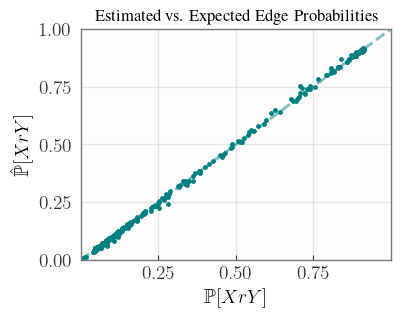

In [14]:
fig, ax = plt.subplots(figsize=(4, 3))

for t, e in zip(tmarg, emarg):
    ax.scatter(t, e, c="teal", s=6)

ax.axline((0, 0), slope=1, linestyle="--", color="teal", alpha=.5)

lim = -1e-6, 1+1e-6 
ax.set_xlim(*lim)
ax.set_ylim(*lim)

ax.set_xticks([.25, .5, .75])

ax.set_xlabel("$\\mathbb{P}[XrY]$")
ax.set_ylabel("$\\hat{\\mathbb{P}}[XrY]$")
ax.set_title("Estimated vs. Expected Edge Probabilities", size=12)
plt.savefig("figures/dags.pdf", bbox_inches="tight")